# Test 7 – Normal unattended operation (archive T8)
Pi left untouched from 14:00 UTC on 24 Oct to 20:30 UTC on 25 Oct (16:00–22:30 SAST).
Receiver and iperf3 server off until 22:13:10 UTC, on from then.

**Checks:** iperf3 slot rules · traceroute rules · job timing · Wi-Fi readings · stability · device cost (idle vs working).

In [1]:
from pathlib import Path
import json, re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates

DATA   = Path('T8')                                  # extracted T8.tar.gz
IPLOG  = Path('test-006_2026-10-24_221310Z.log')     # iperf3 server log (laptop)
T0, T1 = pd.Timestamp('2026-10-24T14:00Z'), pd.Timestamp('2026-10-25T20:30Z')
RX_ON  = pd.Timestamp('2026-10-24T22:13:10Z')        # receiver + iperf3 server started

pd.set_option('display.width', 200)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
UP, DOWN, FAIL, IDLE_BG = '#2563eb', '#ea580c', '#b91c1c', '#e5e7eb'

In [2]:
SKIP = ('vm_', 'go_', 'process_', 'flag', 'scrape_', 'up')
def load(path, keep):
    rows = []
    for line in __import__('gzip').open(path, 'rt'):
        d = json.loads(line); m = d['metric']; n = m['__name__']
        if not any(n.startswith(k) for k in keep): continue
        lab = json.dumps({k: v for k, v in m.items() if k != '__name__'}, sort_keys=True)
        rows.append(pd.DataFrame({'name': n, 'labels': lab,
                                  't': pd.to_datetime(d['timestamps'], unit='ms', utc=True),
                                  'v': d['values']}))
    df = pd.concat(rows, ignore_index=True)
    return df[(df.t >= T0) & (df.t < T1)]

df = load(DATA/'pi_db.jsonl.gz', ['iperf_', 'ping_status', 'snmp_in_bps', 'snmp_out_bps', 'wifi_', 'pi_',
                                'monitor_backhaul', 'ping_loss_pct', 'traceroute_run_info', 'traceroute_hops_reached',
                                'vmagent_remotewrite_pending_data_bytes', 'vmagent_remotewrite_bytes_sent_total',
                                'vmagent_remotewrite_packets_dropped_total', 'process_resident_memory_bytes'])
def ser(name, contains=None):
    x = df[df.name == name]
    if contains: x = x[x.labels.str.contains(contains, regex=False)]
    return x.groupby('t').v.sum().sort_index()

pending = ser('vmagent_remotewrite_pending_data_bytes')
DRAINED = pending[RX_ON:][pending[RX_ON:] == 0].index[0]      # backlog fully sent
W = {'idle': (T0, RX_ON), 'working': (DRAINED, T1)}
print('Backlog at receiver start: %.2f MB, sent by %s (%.1f min)' %
      (pending[:RX_ON].iloc[-1]/1e6, DRAINED.strftime('%H:%M:%S'), (DRAINED-RX_ON).total_seconds()/60))
for k, (a, b) in W.items(): print(f'{k:8s} {a:%d %H:%M:%S} – {b:%d %H:%M:%S} UTC  ({(b-a).total_seconds()/3600:.1f} h)')

Backlog at receiver start: 9.15 MB, sent by 22:19:30 (6.3 min)
idle     24 14:00:00 – 24 22:13:10 UTC  (8.2 h)
working  24 22:19:30 – 25 20:30:00 UTC  (22.2 h)


## 1. iperf3 slot rules

In [3]:
ip = df[df.name.str.startswith('iperf_')].copy()
ip['test'] = ip.labels.map(lambda s: json.loads(s).get('test'))
succ = ip[ip.name == 'iperf_success'].pivot_table(index='t', columns='test', values='v')
att  = ip[ip.name == 'iperf_attempts'].pivot_table(index='t', columns='test', values='v')

# one row per set: group the three tests that ran within 5 min of each other
t_up = succ['tcp_upload'].dropna().index
sets = pd.DataFrame({'t': t_up})
sets['ok'] = [bool(succ.loc[t, 'tcp_upload']) for t in t_up]
sets['tries per test'] = [int(att.loc[t, 'tcp_upload']) for t in t_up]
sast = sets.t.dt.tz_convert('Africa/Johannesburg')
def slot(h): return 'night' if h < 5 else ('morning' if 6 <= h < 12 else ('afternoon' if h < 18 else 'evening'))
sets['slot (SAST)'] = [f'{d:%d %b} {slot(d.hour)}' for d in sast]
sets['time (SAST)'] = sast.dt.strftime('%H:%M')
print(sets[['time (SAST)', 'slot (SAST)', 'ok', 'tries per test']].to_string(index=False))

time (SAST)      slot (SAST)    ok  tries per test
      18:01   24 Oct evening False               3
      19:01   24 Oct evening False               3
      20:01   24 Oct evening False               3
      21:01   24 Oct evening False               3
      22:01   24 Oct evening False               3
      23:01   24 Oct evening False               3
      00:01     25 Oct night False               3
      01:00     25 Oct night  True               1
      06:00   25 Oct morning  True               1
      12:00 25 Oct afternoon  True               1
      18:00   25 Oct evening  True               1


In [4]:
# results of the successful sets: Pi side (DB) + data moved (laptop server log)
thr = ip[ip.name == 'iperf_throughput_mbps'].pivot_table(index='t', columns='test', values='v')
jit = ip[ip.name == 'iperf_jitter_ms'].set_index('t').v
lost = ip[ip.name == 'iperf_lost_pct'].set_index('t').v

log = IPLOG.read_text().splitlines()
summ = [l for l in log if re.search(r'(receiver|sender)\s*$', l)]
def mbytes(l):
    v, u = re.search(r'([\d.]+) (KBytes|MBytes)', l).groups()
    return float(v) / (1024 if u == 'KBytes' else 1) * 1.048576     # MiB -> MB
mb = [mbytes(l) for l in summ]
data_per_set = [sum(mb[i:i+3]) for i in range(0, len(mb), 3)]       # upload, download, UDP

ok = sets[sets.ok].reset_index(drop=True)
tab_iperf = pd.DataFrame({
    'Slot (SAST)': ok['slot (SAST)'], 'Start (UTC)': ok.t.dt.strftime('%d %H:%M:%S').values,
    'Upload (Mbit/s)':   [thr.loc[t, 'tcp_upload'] for t in ok.t],
    'Download (Mbit/s)': [thr.loc[thr.index > t, 'tcp_download'].dropna().iloc[0] for t in ok.t],
    'UDP jitter (ms)':   [jit[jit.index > t].iloc[0] for t in ok.t],
    'UDP loss (%)':      [lost[lost.index > t].iloc[0] for t in ok.t],
    'Data (MB)':         np.round(data_per_set, 1)})
tab_iperf

,Slot (SAST),Start (UTC),Upload (Mbit/s),Download (Mbit/s),UDP jitter (ms),UDP loss (%),Data (MB)
0,25 Oct night,24 23:00:13,11.53,10.90,6.264,0.0,29.4
1,25 Oct morning,25 04:00:09,14.25,10.28,4.835,0.0,32.7
2,25 Oct afternoon,25 10:00:06,13.36,11.43,3.841,0.0,32.3
3,25 Oct evening,25 16:00:02,2.50,7.76,23.100,0.0,13.7


In [5]:
# was the link quiet before each set? (night: last 5 min < 1/0.5 Mbit/s; day: last 1 min < 7/3.5 Mbit/s)
rin, rout = ser('snmp_in_bps')/1e6, ser('snmp_out_bps')/1e6
rows = []
for t, s in zip(ok.t, ok['slot (SAST)']):
    w = 5 if 'night' in s else 1
    a = t - pd.Timedelta(minutes=w)
    rows.append([s, w, rin[a:t].max(), rout[a:t].max(), '1 / 0.5' if w == 5 else '7 / 3.5'])
pd.DataFrame(rows, columns=['Slot', 'Window (min)', 'Max in (Mbit/s)', 'Max out (Mbit/s)', 'Limit in/out'])

,Slot,Window (min),Max in (Mbit/s),Max out (Mbit/s),Limit in/out
0,25 Oct night,5,0.011430,0.022474,1 / 0.5
1,25 Oct morning,1,0.004251,0.010847,7 / 3.5
2,25 Oct afternoon,1,0.009686,0.022270,7 / 3.5
3,25 Oct evening,1,0.004315,0.010390,7 / 3.5


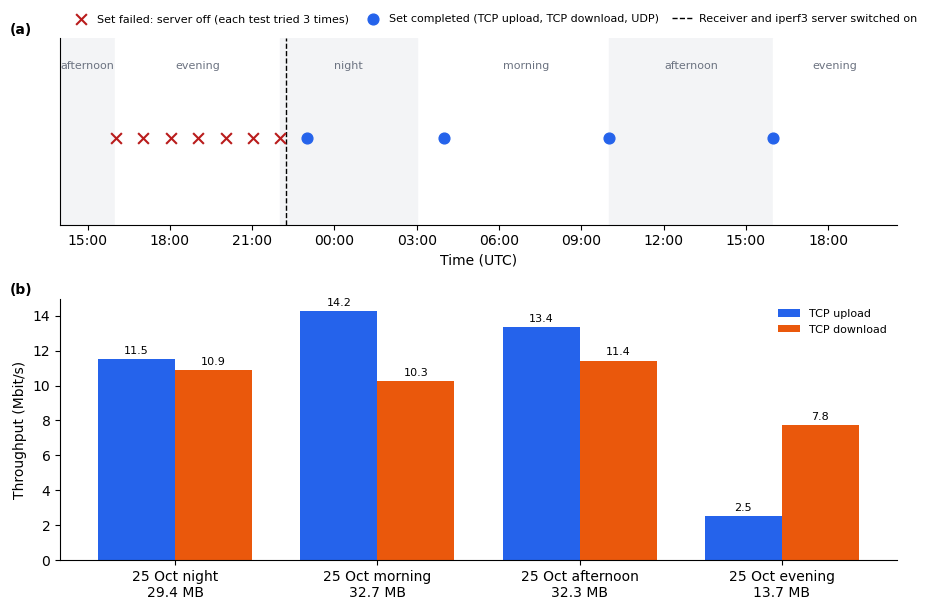

In [18]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6.2), gridspec_kw={'height_ratios': [1, 1.4]})
# (a) every try, with the SAST slots in the background
for d0 in pd.date_range('2026-10-24', '2026-10-26', freq='D', tz='Africa/Johannesburg'):
    for h0, h1, name in [(0, 5, 'night'), (6, 12, 'morning'), (12, 18, 'afternoon'), (18, 24, 'evening')]:
        a, b = (d0 + pd.Timedelta(hours=h0)).tz_convert('UTC'), (d0 + pd.Timedelta(hours=h1)).tz_convert('UTC')
        a, b = max(a, T0), min(b, T1)
        if a >= b: continue
        a1.axvspan(a, b, color='#f3f4f6' if name in ('night', 'afternoon') else '#ffffff', zorder=0)
        a1.text(a + (b - a)/2, 1.55, name, ha='center', fontsize=8, color='#6b7280')
f, s_ = sets[~sets.ok], sets[sets.ok]
a1.scatter(f.t, [1]*len(f), marker='x', s=60, color=FAIL, zorder=3,
           label='Set failed: server off (each test tried 3 times)')
a1.scatter(s_.t, [1]*len(s_), marker='o', s=60, color=UP, zorder=3,
           label='Set completed (TCP upload, TCP download, UDP)')
a1.axvline(RX_ON, color='k', ls='--', lw=1, label='Receiver and iperf3 server switched on')
a1.set_ylim(0.3, 1.8); a1.set_yticks([]); a1.set_xlim(T0, T1)
a1.legend(loc='lower left', bbox_to_anchor=(0, 1.02), ncol=3, fontsize=8, frameon=False,
          handletextpad=0.4, columnspacing=1.2)
a1.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M', tz='UTC'))
a1.set_xlabel('Time (UTC)')
a1.text(-0.06, 1.02, '(a)', transform=a1.transAxes, fontsize=10, fontweight='bold')   # panel letter
# (b) result of each completed set
x = np.arange(len(tab_iperf)); wbar = 0.38
a2.bar(x - wbar/2, tab_iperf['Upload (Mbit/s)'], wbar, color=UP, label='TCP upload')
a2.bar(x + wbar/2, tab_iperf['Download (Mbit/s)'], wbar, color=DOWN, label='TCP download')
for i, r in tab_iperf.iterrows():
    a2.text(i - wbar/2, r['Upload (Mbit/s)'] + 0.3, f"{r['Upload (Mbit/s)']:.1f}", ha='center', fontsize=8)
    a2.text(i + wbar/2, r['Download (Mbit/s)'] + 0.3, f"{r['Download (Mbit/s)']:.1f}", ha='center', fontsize=8)
a2.set_xticks(x, [f"{s}\n{d} MB" for s, d in zip(tab_iperf['Slot (SAST)'], tab_iperf['Data (MB)'])])
a2.set_ylabel('Throughput (Mbit/s)'); a2.legend(frameon=False, fontsize=8)
a2.text(-0.06, 1.02, '(b)', transform=a2.transAxes, fontsize=10, fontweight='bold')   # panel letter
fig.tight_layout(); fig.savefig('t7_iperf.pdf'); fig.savefig('t7_iperf.png', dpi=200); plt.show()

## 2. Traceroute rules

In [7]:
tr = df[df.name == 'traceroute_run_info'].sort_values('t').copy()
tr['reason'] = tr.labels.map(lambda s: json.loads(s)['reason'])
gap = tr.t.diff().dt.total_seconds() / 60
hops = ser('traceroute_hops_reached')
print(f'runs: {len(tr)}   reasons: {tr.reason.value_counts().to_dict()}')
print(f'time between runs: {gap.min():.1f}–{gap.max():.1f} min (mean {gap.mean():.1f})')
print(f'hops to 8.8.8.8: {int(hops.min())}–{int(hops.max())}')

runs: 31   reasons: {'baseline': 31}
time between runs: 60.0–60.2 min (mean 60.1)
hops to 8.8.8.8: 14–15


## 3. Job timing

In [8]:
span = (T1 - T0).total_seconds()
rows = []
for job, name, iv in [('Wi-Fi', 'wifi_signal_dbm', 2), ('SNMP', 'snmp_in_bps', 10),
                      ('Device health', 'pi_cpu_usage_pct', 10), ('Ping', 'ping_status', 10)]:
    s = ser(name); d = s.index.to_series().diff().dt.total_seconds().dropna()
    rows.append([job, iv, int(span/iv), len(s), 100*len(s)/(span/iv), int((d > 1.5*iv).sum()), d.max()])
tab_timing = pd.DataFrame(rows, columns=['Job', 'Interval (s)', 'Expected', 'Recorded', 'Recorded (%)', 'Gaps', 'Longest gap (s)'])
tab_timing.round(1)

,Job,Interval (s),Expected,Recorded,Recorded (%),Gaps,Longest gap (s)
0,Wi-Fi,2,54900,54900,100.0,0,2.2
1,SNMP,10,10980,10980,100.0,0,10.0
2,Device health,10,10980,10980,100.0,0,10.0
3,Ping,10,10980,10795,98.3,11,265.2


In [9]:
# every ping gap and whether an iperf3 set was running
p = ser('ping_status'); d = p.index.to_series().diff().dt.total_seconds()
g = d[d > 15]
pd.DataFrame({'Gap starts (UTC)': (g.index - pd.to_timedelta(g.values, unit='s')).strftime('%d %H:%M:%S'),
              'Length (s)': g.round(0).values,
              'iperf3 set': ['failed (server off)' if v > 100 else 'completed' for v in g]})

,Gap starts (UTC),Length (s),iperf3 set
0,24 16:00:03,265.0,failed (server off)
1,24 17:00:12,265.0,failed (server off)
2,24 18:00:21,265.0,failed (server off)
3,24 19:00:31,265.0,failed (server off)
4,24 20:00:40,265.0,failed (server off)
5,24 21:00:49,265.0,failed (server off)
6,24 21:59:58,265.0,failed (server off)
7,24 23:00:07,42.0,completed
8,25 04:00:03,42.0,completed
9,25 10:00:00,42.0,completed


## 4. Wi-Fi readings and backhaul state

In [10]:
ws = ser('wifi_status'); sig = ser('wifi_signal_dbm'); rx = ser('wifi_rx_bitrate_mbps'); tx = ser('wifi_tx_bitrate_mbps')
print(f'Wi-Fi connected in {100*(ws==0).mean():.1f} % of {len(ws)} readings')
print(f'signal: median {sig.median():.0f} dBm, range {sig.min():.0f} to {sig.max():.0f} dBm, frequency {ser("wifi_freq_mhz").iloc[0]:.0f} MHz')
print(f'link rate: receive median {rx.median():.0f} Mbit/s, send median {tx.median():.0f} Mbit/s')
st = ser('monitor_backhaul_state'); fs = ser('monitor_backhaul_fail_streak'); loss = ser('ping_loss_pct')
print(f'backhaul up in {100*(st==0).mean():.1f} % of {len(st)} checks; longest fail streak {fs.max():.0f}')
print(f'checks with some loss: {(loss>0).sum()}, with all 5 pings lost: {(loss==100).sum()}')

Wi-Fi connected in 100.0 % of 54900 readings
signal: median -29 dBm, range -32 to -28 dBm, frequency 5200 MHz
link rate: receive median 390 Mbit/s, send median 433 Mbit/s
backhaul up in 100.0 % of 10795 checks; longest fail streak 0
checks with some loss: 13, with all 5 pings lost: 0


## 5. Stability and 6. Device cost

In [11]:
svc = df[df.name == 'pi_service_up'].copy(); svc['service'] = svc.labels.map(lambda s: json.loads(s)['service'])
print('services up in every reading:', svc.groupby('service').v.min().to_dict())
print(open(DATA/'services.txt').read().replace('\n\n', ' | '))
up = ser('pi_uptime_seconds'); print(f'uptime {up.iloc[0]/3600:.1f} -> {up.iloc[-1]/3600:.1f} h (no reboot: {(up.diff().dropna() > 0).all()})')
th = df[df.name == 'pi_throttled']; v = ser('pi_input_voltage_v')
print(f'throttling / under-voltage flags ever set: {int(th.v.max())};  supply {v.min():.2f}–{v.max():.2f} V')

services up in every reading: {'grafana-server': 1.0, 'netmon': 1.0, 'victoria': 1.0, 'vmagent': 1.0}
NRestarts=0
Id=netmon.service
ActiveEnterTimestamp=Sat 2026-10-24 13:53:24 SAST | NRestarts=0
Id=vmagent.service
ActiveEnterTimestamp=Sat 2026-10-24 13:53:24 SAST | NRestarts=0
Id=victoria.service
ActiveEnterTimestamp=Sat 2026-10-24 13:53:24 SAST | NRestarts=0
Id=grafana-server.service
ActiveEnterTimestamp=Sat 2026-10-24 13:53:24 SAST
2026-10-24 13:56:13

uptime 2.1 -> 32.6 h (no reboot: True)
throttling / under-voltage flags ever set: 0;  supply 5.05–5.14 V


In [12]:
cpu, mem, temp, load1 = ser('pi_cpu_usage_pct'), ser('pi_memory_used_pct'), ser('pi_cpu_temp_celsius'), ser('pi_load_avg', '"1m"')
rows = []
for label, f in [('CPU use, mean (%)', lambda s: s.mean()), ('CPU use, 95th percentile (%)', lambda s: s.quantile(.95))]:
    rows.append([label] + [f(cpu[a:b]) for a, b in W.values()])
rows += [['Load average (1 min)'] + [load1[a:b].mean() for a, b in W.values()],
         ['Memory used (%)'] + [mem[a:b].mean() for a, b in W.values()],
         ['CPU temperature, mean (°C)'] + [temp[a:b].mean() for a, b in W.values()],
         ['CPU temperature, max (°C)'] + [temp[a:b].max() for a, b in W.values()]]
tab_cost = pd.DataFrame(rows, columns=['Measure', 'Idle', 'Working']).round(2)
tab_cost

,Measure,Idle,Working
0,"CPU use, mean (%)",0.60,0.62
1,"CPU use, 95th percentile (%)",1.60,1.60
2,Load average (1 min),0.07,0.07
3,Memory used (%),19.91,20.66
4,"CPU temperature, mean (°C)",56.82,56.81
5,"CPU temperature, max (°C)",62.20,62.20


available RAM: 6794 -> 6659 MB, trend -4.24 MB/h (-102 MB/day)
vmagent RAM: 23.0 -> 23.9 MB


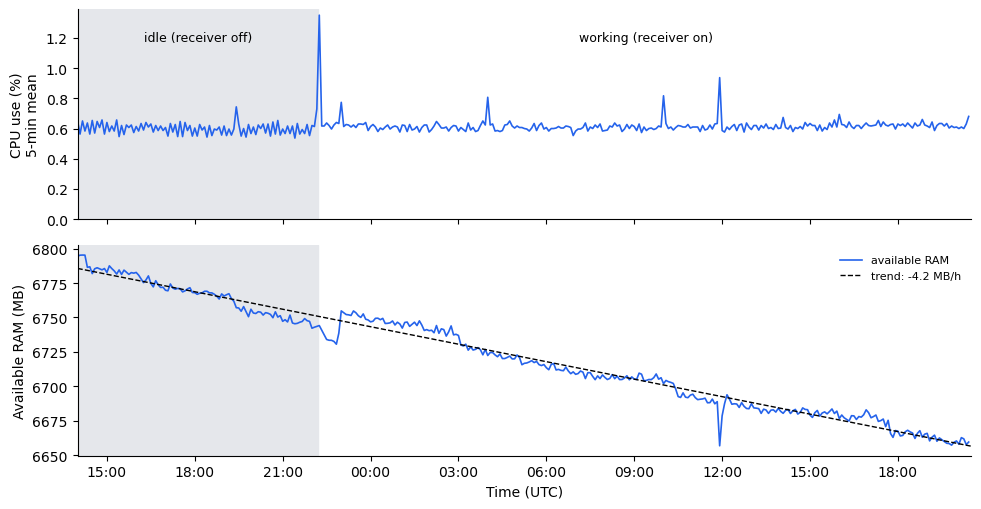

In [19]:
avail = ser('pi_memory_available_bytes') / 1e6
h = (avail.index - avail.index[0]).total_seconds() / 3600
slope, icpt = np.polyfit(h, avail.values, 1)
vma = ser('process_resident_memory_bytes') / 1e6
print(f'available RAM: {avail.iloc[:30].mean():.0f} -> {avail.iloc[-30:].mean():.0f} MB, trend {slope:.2f} MB/h ({24*slope:.0f} MB/day)')
print(f'vmagent RAM: {vma.iloc[:20].mean():.1f} -> {vma.iloc[-20:].mean():.1f} MB')

fig, (b1, b2) = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True)
for ax in (b1, b2):
    ax.axvspan(*W['idle'], color=IDLE_BG, zorder=0)
b1.plot(cpu.resample('5min').mean(), color=UP, lw=1.2)
b1.set_ylabel('CPU use (%)\n5-min mean'); b1.set_ylim(0, None)
b1.text(T0 + (RX_ON - T0)/2, b1.get_ylim()[1]*0.85, 'idle (receiver off)', ha='center', fontsize=9)
b1.text(DRAINED + (T1 - DRAINED)/2, b1.get_ylim()[1]*0.85, 'working (receiver on)', ha='center', fontsize=9)
b2.plot(avail.resample('5min').mean(), color=UP, lw=1.2, label='available RAM')
b2.plot(avail.index, icpt + slope*h, color='k', ls='--', lw=1, label=f'trend: {slope:.1f} MB/h')
b2.set_ylabel('Available RAM (MB)'); b2.legend(frameon=False, fontsize=8)
b2.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M', tz='UTC')); b2.set_xlabel('Time (UTC)'); b2.set_xlim(T0, T1)
fig.tight_layout(); fig.savefig('t7_resources.pdf'); fig.savefig('t7_resources.png', dpi=200); plt.show()

## Data stored and sent per day

In [14]:
sent = ser('vmagent_remotewrite_bytes_sent_total'); a, b = W['working']
rate = (sent[b - pd.Timedelta(seconds=30):b].iloc[-1] - sent[a:].iloc[0]) / (b - a).total_seconds()
idle_p = pending[:RX_ON]; hh = (idle_p.index - idle_p.index[0]).total_seconds()/3600
grow = np.polyfit(hh, idle_p.values, 1)[0]
size_txt = open(DATA/'db_size_now.txt').read().split()
db_bytes = float(size_txt[0]); db_age_h = (pd.Timestamp('2026-10-25T21:13:20Z') - pd.Timestamp('2026-10-23T22:15Z')).total_seconds()/3600
print(f'sent to receiver (normal): {rate:.0f} B/s = {rate*86400/1e6:.1f} MB/day')
print(f'buffer growth while receiver off: {grow/1e6:.3f} MB/h')
print(f'local database: {db_bytes/1e6:.2f} MB after {db_age_h:.0f} h = {db_bytes/1e6/db_age_h*24:.1f} MB/day (assumes DB emptied 22:15 UTC 23 Oct)')
print('vmagent dropped packets:', int(ser('vmagent_remotewrite_packets_dropped_total').max()))

sent to receiver (normal): 262 B/s = 22.6 MB/day
buffer growth while receiver off: 0.962 MB/h
local database: 7.28 MB after 47 h = 3.7 MB/day (assumes DB emptied 22:15 UTC 23 Oct)
vmagent dropped packets: 0
